# Beton Basınç Dayanımı Tahmini: Regression ve Classification

Beton, inşaat mühendisliğinin en önemli malzemesi. Betonun basınç dayanımı, karışımdaki malzemelerin miktarına ve betonun kaç gündür kürlendiğine (yaşına) bağlı, doğrusal olmayan bir fonksiyon.

Bu ödevde iki problem çözeceğiz:
- **Problem 1 - Regression:** Bir beton karışımının malzeme miktarlarından ve yaşından basınç dayanımını (MPa) tahmin etmek.
- **Problem 2 - Classification:** Aynı veriyi sınıflandırmaya uygun hale getirip betonun sınıfını (non-structural, residential, commercial, high-strength) tahmin etmek.

Her iki problemde de önce bir başlangıç (baseline) skoru alacağız, sonra derslerdeki `algo_test` fonksiyonlarıyla en az 7 klasik makine öğrenmesi algoritmasını ve Keras ile bir derin öğrenme modelini karşılaştıracağız. Hedefimiz regression'da R² > 0.80, classification'da accuracy > 0.80.

Veri seti: UCI Concrete Compressive Strength (I-Cheng Yeh, 1998), 1.030 beton karışımı. Malzemeler kg/m³, yaş gün, dayanım MPa cinsinden.

**Ne yapıyoruz:** Kullanacağımız kütüphaneleri yüklüyoruz.

In [1]:
import pandas as pd # tablo işlemleri
import numpy as np # matematik paketi
import matplotlib.pyplot as plt # grafik çizimi
import seaborn as sns # istatistiksel grafikler

**Ne yapıyoruz:** Veriyi okuyup ödevde verilen kodla sütun adlarını değiştiriyoruz.

In [2]:
df=pd.read_csv('concrete.csv') # veriyi oku
df.columns = ['Cement', 'Slag', 'FlyAsh', 'Water', 'Plasticizer',  'CoarseAgg', 'FineAgg', 'Age', 'Strength'] # ödevde verilen sütun adları
df.head() # ilk 5 satır

,Cement,Slag,FlyAsh,Water,Plasticizer,CoarseAgg,FineAgg,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


# Problem 1: Regression

### EDA

In [3]:
df.shape # satır ve sütun sayısı

(1030, 9)

In [4]:
df.info() # veri tipleri

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Cement       1030 non-null   float64
 1   Slag         1030 non-null   float64
 2   FlyAsh       1030 non-null   float64
 3   Water        1030 non-null   float64
 4   Plasticizer  1030 non-null   float64
 5   CoarseAgg    1030 non-null   float64
 6   FineAgg      1030 non-null   float64
 7   Age          1030 non-null   int64  
 8   Strength     1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
df.isnull().sum() # boş veri kontrolü

Cement         0
Slag           0
FlyAsh         0
Water          0
Plasticizer    0
CoarseAgg      0
FineAgg        0
Age            0
Strength       0
dtype: int64

**Sonuç:** 1.030 karışım ve 9 sütun var; bütün sütunlar sayısal ve boş veri yok. Veri scikit-learn için uygun formatta: ek bir dönüşüm gerekmiyor.

In [6]:
df.duplicated().sum() # tekrar eden satır sayısı

np.int64(25)

**Sonuç:** 25 satır başka bir satırla birebir aynı. Aynı karışım laboratuvarda birden fazla kez denenmiş olabilir. Derslerde tekrar eden satırları silme yöntemi görmediğimiz için veriyi olduğu gibi kullanıyoruz.

In [7]:
df.describe() # istatistiksel veriler

,Cement,Slag,FlyAsh,Water,Plasticizer,CoarseAgg,FineAgg,Age,Strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


**Sonuç:** Dayanım 2,3 ile 82,6 MPa arasında, ortalaması 35,8 MPa. Malzeme miktarlarının ölçekleri çok farklı: çimento 102-540, süperakışkanlaştırıcı 0-32 kg/m³. Cüruf, uçucu kül ve süperakışkanlaştırıcı birçok karışımda hiç kullanılmamış (değer 0). Yaş 1 ile 365 gün arasında; karışımların çoğu 28 günlük ölçülmüş.

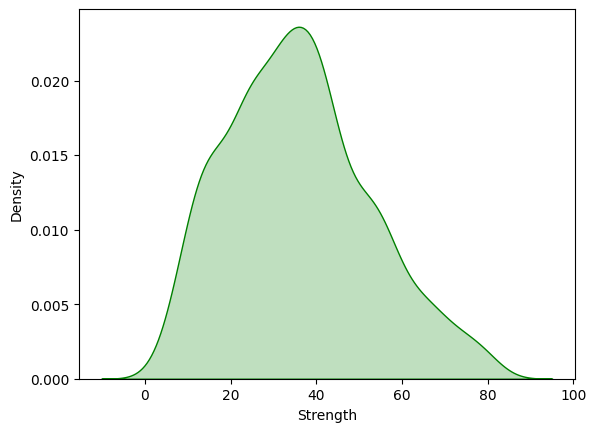

In [8]:
sns.kdeplot(x=df['Strength'], fill=True, color='green'); # dayanımın dağılımı

<Axes: >

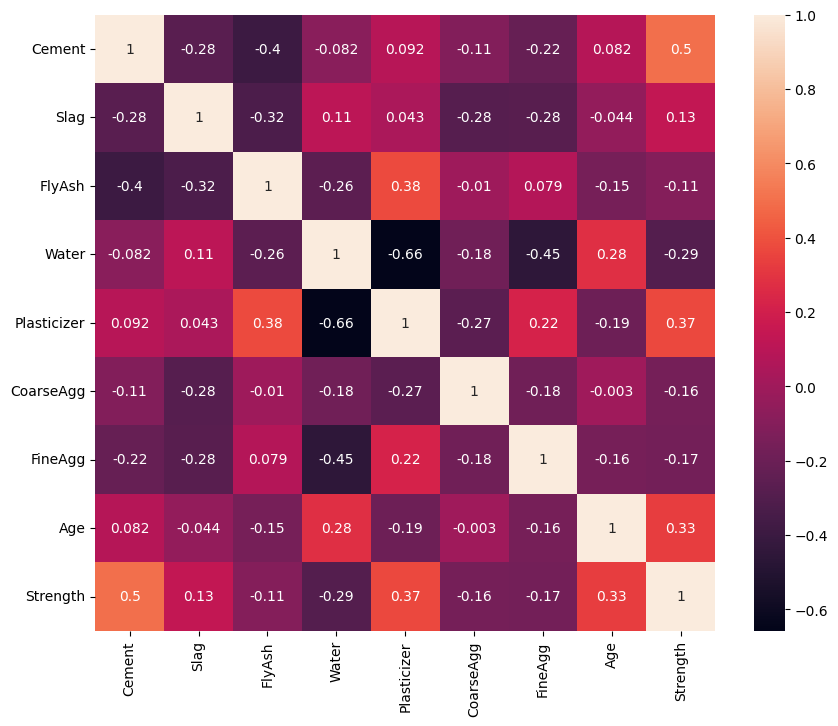

In [9]:
plt.figure(figsize=(10,8)) # grafik boyutu
sns.heatmap(df.corr(numeric_only=True), annot=True) # korelasyon tablosu

In [10]:
abs(df.corr(numeric_only=True))['Strength'].sort_values(ascending=False) # korelasyonu büyükten küçüğe sırala

Strength       1.000000
Cement         0.497832
Plasticizer    0.366079
Age            0.328873
Water          0.289633
FineAgg        0.167241
CoarseAgg      0.164935
Slag           0.134829
FlyAsh         0.105755
Name: Strength, dtype: float64

**Sonuç:** Dayanımla en çok ilişkili özellik çimento (0,50); çimento arttıkça beton güçleniyor. Sonra süperakışkanlaştırıcı (0,37), yaş (0,33) ve su (0,29) geliyor. Isı tablosunda su ile dayanım arasındaki ilişki negatif: su arttıkça beton zayıflıyor. Hiçbir korelasyon 0,50'yi geçmiyor; dayanım tek bir malzemeye değil, malzemelerin birleşimine bağlı. Bu da ödevde belirtildiği gibi ilişkinin doğrusal olmadığını gösteriyor.

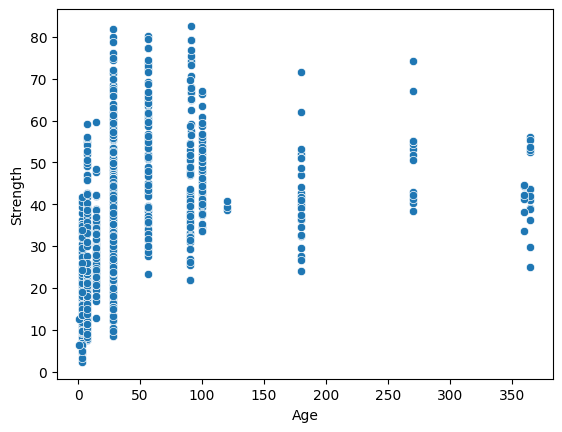

In [11]:
sns.scatterplot(x=df['Age'], y=df['Strength']); # yaş ve dayanım

**Sonuç:** Beton zamanla güçleniyor, ama bu artış doğrusal değil. Ortalama dayanım 3. günde 19, 7. günde 26, 28. günde 37, 56. günde 52 MPa. 90 günden sonra artış yavaşlıyor ve ortalama 40-50 MPa civarında kalıyor. Grafikte noktaların belli günlerde (3, 7, 28, 56, 90, 180, 365) dikey sütunlar oluşturduğu görülüyor; dayanım standart test günlerinde ölçülmüş. Aynı yaştaki betonların dayanımı ise malzemelere göre çok farklı.

### Özellikler (x) ve hedef (y)

**Ne yapıyoruz:** Derslerdeki gibi hedef sütunu (Strength) silip kalan 8 sütunu x, Strength sütununu y olarak ayırıyoruz.

In [12]:
x=df.drop('Strength', axis=1) # 8 özellik
y=df[['Strength']] # hedef: basınç dayanımı
x.shape, y.shape # boyutlar

((1030, 8), (1030, 1))

In [13]:
from sklearn.model_selection import train_test_split # veriyi bölme
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error # başarı ölçüleri
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.20, random_state=42) # %80 eğitim %20 test
x_train.shape, x_test.shape # eğitim ve test boyutu

((824, 8), (206, 8))

**Sonuç:** 824 karışım eğitim, 206 karışım test için ayrıldı. 8 özellikli bir model için 824 eğitim örneği yeterli; test verisindeki 206 örnek de modeli güvenilir şekilde ölçmek için yeterli.

### Başlangıç (baseline) modeli: Linear Regression

**Ne yapıyoruz:** Ödevdeki formüldeki gibi (y = β0 + β1x1 + ... + β8x8) her malzeme için bir katsayı öğrenen Linear Regression modelini kuruyoruz. Bu modelin skoru, diğer modellerin ne kadar ilerleme sağladığını ölçmek için başlangıç noktası olacak.

In [14]:
from sklearn.linear_model import LinearRegression # doğrusal regresyon
lr=LinearRegression() # modeli oluştur
model=lr.fit(x_train,y_train) # modeli eğit
tahmin=lr.predict(x_test) # tahmin
r2_score(y_test,tahmin) # başarı oranı

0.627553179231485

In [15]:
mean_squared_error(y_test,tahmin)**.5, mean_absolute_error(y_test,tahmin) # RMSE ve MAE (MPa)

(9.79647590162436, 7.745559243921434)

**Sonuç:** Başlangıç (baseline) modelinin skoru R² 0,628; tahminler ortalama 7,7 MPa sapıyor. Bu skor hedefin altında ve diğer modellerin karşılaştırılacağı başlangıç noktası.

In [16]:
fi=pd.DataFrame({'Feature':x_train.columns, 'Coef':model.coef_[0]}) # β katsayıları
fi['Coef']=fi['Coef'].round(3) # 3 ondalık
fi # her malzemenin katsayısı

,Feature,Coef
0,Cement,0.119
1,Slag,0.109
2,FlyAsh,0.082
3,Water,-0.135
4,Plasticizer,0.311
5,CoarseAgg,0.018
6,FineAgg,0.024
7,Age,0.116


In [17]:
model.intercept_ # β0 sabit değeri

array([-28.823555])

**Sonuç:** Formüldeki β katsayıları: her kg çimento dayanımı 0,119 MPa, her kg cüruf 0,109, uçucu kül 0,082 ve süperakışkanlaştırıcı 0,311 MPa artırıyor; her kg su ise 0,135 MPa azaltıyor. Her gün yaş 0,116 MPa ekliyor. Ancak yaş grafiğinde gördüğümüz gibi gerçekte dayanım 90 günden sonra artmıyor; doğrusal model bunu bilemediği için 365 günlük betonlara çok yüksek dayanım tahmin ediyor. Başlangıç modelinin düşük kalmasının ana sebeplerinden biri bu.

### En az 7 klasik algoritma: algo_test

**Ne yapıyoruz:** Derslerdeki regression.py dosyasındaki `algo_test` fonksiyonunu kullanıyoruz. Fonksiyon 9 algoritmayı (Linear, Ridge, Lasso, ElasticNet, Extra Tree, Gradient Boosting, KNN, Decision Tree, XGBoost) aynı veriyle eğitip R², RMSE ve MAE değerlerini tek tabloda veriyor. regression.py'nin başındaki uyarıları gizleme ve sütun gösterme satırları bu notebook'ta kullanılmadığı için çıkarıldı; fonksiyon aynen kullanıldı.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge,Lasso
from sklearn.linear_model import ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import ExtraTreeRegressor
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error


def algo_test(x,y):
        #Bütün modelleri tanımlıyorum
        L=LinearRegression()
        R=Ridge()
        Lass=Lasso()
        E=ElasticNet()
        ETR=ExtraTreeRegressor()
        GBR=GradientBoostingRegressor()
        kn=KNeighborsRegressor()
        dt=DecisionTreeRegressor()
        xgb=XGBRegressor()
       
        
        algos=[L,R,Lass,E,ETR,GBR,kn,dt,xgb]
        algo_names=['Linear','Ridge','Lasso','ElasticNet','Extra Tree','Gradient Boosting','KNeighborsRegressor','Decision Tree','XGBRegressor']
        
        x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=.2,random_state=42)
        
        r_squared= []
        rmse= []
        mae= []
        
        #Hata ve doğruluk oranlarını bir tablo haline getirmek için bir dataframe oluşturuyorum
        result=pd.DataFrame(columns=['R_Squared','RMSE','MAE'],index=algo_names)
        
        
        for algo in algos:
            p=algo.fit(x_train,y_train).predict(x_test)
            r_squared.append(r2_score(y_test,p))
            rmse.append(mean_squared_error(y_test,p)**.5)
            mae.append(mean_absolute_error(y_test,p))
        
            

        #result adlı tabloya doğruluk ve hata oranlarımı yerleştiriyorum
        result.R_Squared=r_squared
        result.RMSE=rmse
        result.MAE=mae
        
       #oluşturduğum result tablosunu doğruluk oranına (r2_score) göre sıralayıp dönüyor
        rtable=result.sort_values('R_Squared',ascending=False)
        return rtable

In [19]:
algo_test(x,y) # 9 algoritmayı karşılaştır

/usr/local/lib/python3.12/dist-packages/sklearn/ensemble/_gb.py:680: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


,R_Squared,RMSE,MAE
XGBRegressor,0.917138,4.620778,3.034498
Gradient Boosting,0.883603,5.476562,4.125856
Decision Tree,0.834848,6.523476,4.292184
Extra Tree,0.806374,7.063491,4.354175
KNeighborsRegressor,0.733024,8.294182,6.480971
ElasticNet,0.627650,9.795197,7.743225
Lasso,0.627598,9.795886,7.743431
Ridge,0.627553,9.796474,7.745554
Linear,0.627553,9.796476,7.745559


**Sonuç:** 9 algoritmanın 4'ü %80 hedefini geçti. En iyi model **XGBoost** (R² 0,917, ortalama hata 3,0 MPa); başlangıç modeline göre 29 puanlık bir ilerleme. Gradient Boosting (0,884), Decision Tree ve Extra Tree de hedefi geçti. Doğrusal modellerin dördü (Linear, Ridge, Lasso, ElasticNet) 0,628'de kaldı: ilişki doğrusal olmadığı için katsayıları küçültmek fark yaratmıyor. Ağaç modelleri, yaşın etkisinin 90 günden sonra durması gibi doğrusal olmayan ilişkileri öğrenebildiği için çok daha başarılı. algo_test içindeki ağaç modellerinde random_state olmadığı için Decision Tree ve Extra Tree satırları her çalıştırmada biraz değişebilir.

### Deep Learning: Keras

**Ne yapıyoruz:** Derslerdeki Deep Learning yapısıyla bir sinir ağı kuruyoruz. Sinir ağları sayıların büyüklüğüne duyarlı olduğu için derslerdeki StandardScaler'ı sadece eğitim verisiyle öğretiyoruz (`fit_transform`), test verisini aynı kuralla dönüştürüyoruz (`transform`). Derslerdeki gibi EarlyStopping kullanıyoruz.

In [20]:
from sklearn.preprocessing import StandardScaler # ölçeklendirme
sc=StandardScaler() # scaler
x_train_sc=sc.fit_transform(x_train) # eğitim verisiyle öğren ve dönüştür
x_test_sc=sc.transform(x_test) # test verisini aynı kuralla dönüştür

In [21]:
from keras.models import Sequential # katmanları sırayla dizen model
from keras.layers import Dense # tam bağlantılı katman
from keras.callbacks import EarlyStopping # erken durdurma

I0000 00:00:1792689979.824303     119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792689995.335833     119 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792690003.529504     119 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [22]:
model_r=Sequential() # boş model
model_r.add(Dense(64, activation='relu')) # 64 nöronlu gizli katman
model_r.add(Dense(32, activation='relu')) # 32 nöronlu gizli katman
model_r.add(Dense(16, activation='relu')) # 16 nöronlu gizli katman
model_r.add(Dense(1)) # regression olduğu için tek nöron, aktivasyon yok
model_r.compile(loss='mean_squared_error', optimizer='adam') # modeli derle
early_stop=EarlyStopping(monitor='val_loss', patience=20) # 20 epoch iyileşme olmazsa dur
history_r=model_r.fit(x_train_sc, y_train, epochs=1000, batch_size=16, validation_split=0.2, verbose=0, callbacks=[early_stop]) # modeli eğit
len(history_r.history['loss']) # kaç epoch eğitildi

148

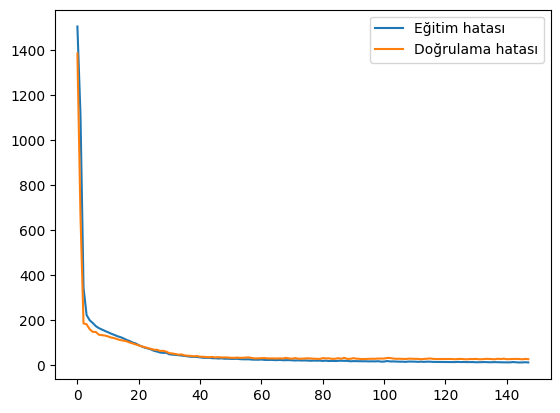

In [23]:
plt.plot(history_r.history['loss'], label='Eğitim hatası') # eğitim kaybı
plt.plot(history_r.history['val_loss'], label='Doğrulama hatası') # doğrulama kaybı
plt.legend(); # açıklama kutusu

In [24]:
ktahmin=model_r.predict(x_test_sc, verbose=0) # tahmin
r2_score(y_test,ktahmin), mean_squared_error(y_test,ktahmin)**.5, mean_absolute_error(y_test,ktahmin) # R², RMSE, MAE

(0.8312074542045593, 6.594992859484413, 4.443361759185791)

**Sonuç:** Keras modeli R² yaklaşık 0,83, ortalama hata yaklaşık 4,4 MPa; hedefi geçti. Sinir ağı, başlangıç modelinden çok daha iyi ama XGBoost'un (0,917) gerisinde. 1.030 satırlık küçük ve tablo şeklindeki bir veride ağaç tabanlı modeller genellikle sinir ağlarından daha başarılı. EarlyStopping, doğrulama hatası 20 epoch boyunca iyileşmeyince eğitimi durdurdu. Sinir ağı rastgele başladığı için sonuç her çalıştırmada biraz değişebilir.

### Problem 1 karşılaştırma

In [25]:
karsilastirma=pd.DataFrame() # gerçek ve tahmin tablosu
karsilastirma['Gercek']=y_test['Strength'] # gerçek dayanım
karsilastirma['Linear']=tahmin.ravel().round(1) # başlangıç modeli
karsilastirma['Keras']=ktahmin.ravel().round(1) # sinir ağı
karsilastirma.head(10) # ilk 10 karışım

,Gercek,Linear,Keras
31,52.91,59.7,46.000000
109,55.90,52.0,40.500000
136,74.50,63.5,72.599998
88,35.30,51.6,34.700001
918,10.54,17.2,12.800000
1025,44.28,39.9,48.099998
870,23.69,26.7,29.000000
318,45.37,44.7,55.299999
261,37.40,29.4,32.200001
535,48.85,38.2,45.799999


**Sonuç:** Keras tahminleri genelde gerçeğe Linear Regression'dan daha yakın; örneğin 74,5 MPa'lık beton için Keras 72,6, Linear 63,5 tahmin etti. Kaydedilen XGBoost modeli de ilk üç karışım için 52,8, 41,0 ve 72,7 MPa tahmin etti (gerçek: 52,9, 55,9, 74,5).

### En iyi regression modelini kaydetme

**Ne yapıyoruz:** algo_test tablosunda en iyi model XGBoost. Derslerdeki algo_test'teki ayarlarla aynı modeli eğitim verisiyle eğitip joblib ile kaydediyoruz.

In [26]:
import joblib # dosya kaydetme kütüphanesi
from xgboost import XGBRegressor # XGBoost
xgb=XGBRegressor() # algo_test'teki ayarlar
xgb.fit(x_train,y_train) # eğitim verisiyle eğit
xtahmin=xgb.predict(x_test) # tahmin
r2_score(y_test,xtahmin) # başarı oranı (algo_test ile aynı olmalı)

0.9171381592750549

In [27]:
joblib.dump(xgb,'beton_dayanim_model.pkl') # modeli kaydet
joblib.load('beton_dayanim_model.pkl').predict(x_test[:3]), y_test[:3].values.ravel() # kaydedilen model: tahmin ve gerçek

(array([52.815117, 41.047356, 72.65362 ], dtype=float32),
 array([52.91, 55.9 , 74.5 ]))

# Problem 2: Classification

**Ne yapıyoruz:** Ödevde verilen kodla regression verisini sınıflandırmaya uygun hale getiriyoruz. `green_classifier` karışımda cüruf ve uçucu kül gibi çevre dostu malzemelerin yeterince olup olmadığına bakıyor. `strength_classifer` dayanımı NRMCA standardına göre 4 sınıfa ayırıyor. Plasticizer sütunu evet/hayır metnine çevriliyor ve Strength sütunu siliniyor; çünkü sınıf zaten dayanımdan hesaplandı ve dayanım modelde kalırsa model cevabı doğrudan görür.

In [28]:
def green_classifier(s): # ödevde verilen fonksiyon
    """
    Use numeric data to create a Green categorical feature.
    """
    if (s.Slag + s.FlyAsh < 150.0) and (s.Plasticizer < 10.0): # az çevre dostu malzeme
        return "n/a" # yeşil değil
    else: # yeterli çevre dostu malzeme
        return "green" # yeşil beton

def strength_classifer(x): # ödevde verilen fonksiyon
    """
    Use numeric data to create a ConcreteClass categorical feature.  This is
    based on "CIP 35 - Testing Compressive Strength of Concrete", National
    Ready Mixed Concrete Association (www.nrmca.org), 2003 & 2014.
    """
    if x < 17.0: # 17 MPa altı
        return "non-structural" # taşıyıcı olmayan
    elif x < 28.0: # 17-28 MPa
        return "residential" # konut
    elif x < 70.0: # 28-70 MPa
        return "commercial" # ticari
    else: # 70 MPa ve üzeri
        return "high-strength" # yüksek dayanımlı

In [29]:
# create new categorical targets
df["Green"] = df.apply(green_classifier, axis=1) # yeşil beton sütunu
df["ConcreteClass"] = df.Strength.apply(strength_classifer) # beton sınıfı sütunu

# convert Plasticizer to text (the numeric values are embedded in Green)
df.Plasticizer = df.Plasticizer.apply(lambda x: "yes" if x > 0 else "no") # süperakışkanlaştırıcı var mı

# remove Strength feature as replaced by categorical target ConcreteClass
df.drop("Strength", axis=1, inplace=True) # dayanım sütununu sil
df.head() # yeni tablo

,Cement,Slag,FlyAsh,Water,Plasticizer,CoarseAgg,FineAgg,Age,Green,ConcreteClass
0,540.0,0.0,0.0,162.0,yes,1040.0,676.0,28,n/a,high-strength
1,540.0,0.0,0.0,162.0,yes,1055.0,676.0,28,n/a,commercial
2,332.5,142.5,0.0,228.0,no,932.0,594.0,270,n/a,commercial
3,332.5,142.5,0.0,228.0,no,932.0,594.0,365,n/a,commercial
4,198.6,132.4,0.0,192.0,no,978.4,825.5,360,n/a,commercial


### EDA

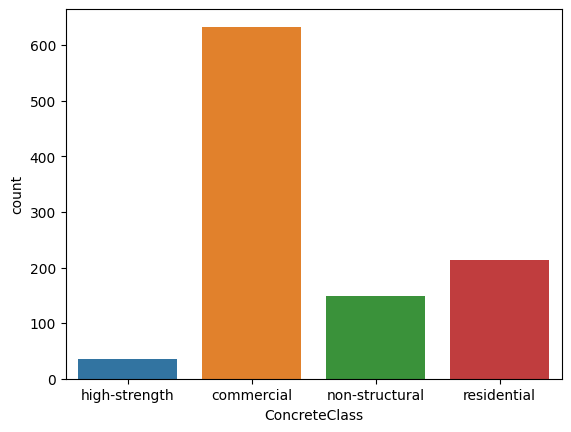

In [30]:
sns.countplot(x=df['ConcreteClass'], hue=df['ConcreteClass']); # sınıfların dağılımı

In [31]:
df['ConcreteClass'].value_counts() # her sınıftan kaç karışım var

ConcreteClass
commercial        633
residential       213
non-structural    148
high-strength      36
Name: count, dtype: int64

**Sonuç:** Sınıflar dengesiz: karışımların %61'i (633) commercial, sadece %3,5'i (36) high-strength. Herkese 'commercial' diyen bir model bile %61 doğruluk alır. high-strength sınıfında çok az örnek olduğu için bu sınıfı öğrenmek zor olacak.

In [32]:
df.groupby('Green')['ConcreteClass'].value_counts() # yeşil ve yeşil olmayan betonlarda sınıflar

Green  ConcreteClass 
green  commercial        370
       residential        97
       non-structural     65
       high-strength      28
n/a    commercial        263
       residential       116
       non-structural     83
       high-strength       8
Name: count, dtype: int64

**Sonuç:** 36 high-strength betonun 28'i yeşil beton (cüruf, uçucu kül veya süperakışkanlaştırıcı oranı yüksek karışımlar). Yeşil betonlarda high-strength oranı %5, diğer betonlarda %1,7. Bu tablo, çevre dostu malzemelerin yüksek dayanımlı beton üretmeye engel olmadığını gösteriyor; ancak bu malzemelerin dayanımı doğrudan artırdığını söylemek için karışımın diğer özelliklerine de bakmak gerekir.

### Özellikler (x) ve hedef (y)

**Ne yapıyoruz:** Plasticizer ve Green sütunları metin olduğu için derslerdeki `get_dummies` ile 0-1 sütunlara çeviriyoruz.

In [33]:
x=df.drop('ConcreteClass', axis=1) # özellikler
y=df['ConcreteClass'] # hedef: beton sınıfı
x=pd.get_dummies(x, drop_first=True) # metin sütunlarını 0-1 sütunlara çevir
x.head() # özellikler

,Cement,Slag,FlyAsh,Water,CoarseAgg,FineAgg,Age,Plasticizer_yes,Green_n/a
0,540.0,0.0,0.0,162.0,1040.0,676.0,28,True,True
1,540.0,0.0,0.0,162.0,1055.0,676.0,28,True,True
2,332.5,142.5,0.0,228.0,932.0,594.0,270,False,True
3,332.5,142.5,0.0,228.0,932.0,594.0,365,False,True
4,198.6,132.4,0.0,192.0,978.4,825.5,360,False,True


In [34]:
x_train, x_test, y_train, y_test=train_test_split(x,y, test_size=0.20, random_state=42) # %80 eğitim %20 test
y_test.value_counts() # test verisindeki sınıflar

ConcreteClass
commercial        133
residential        35
non-structural     32
high-strength       6
Name: count, dtype: int64

**Sonuç:** Test verisinde 206 karışım var; ama high-strength sınıfından sadece 6 örnek. Bu sınıfın sonuçları çok az örneğe dayandığı için güvenilir değil.

### Başlangıç (baseline) modeli: Logistic Regression

In [35]:
from sklearn.linear_model import LogisticRegression # lojistik regresyon
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report # başarı ölçüleri
L=LogisticRegression(max_iter=1000) # modeli oluştur
Ltahmin=L.fit(x_train,y_train).predict(x_test) # eğit ve tahmin et
accuracy_score(y_test,Ltahmin) # doğruluk oranı

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.7961165048543689

**Sonuç:** Başlangıç (baseline) sınıflandırma modeli Logistic Regression %79,6 accuracy aldı; hedefin hemen altında.

### En az 7 klasik algoritma: algo_test

**Ne yapıyoruz:** Derslerdeki classification.py dosyasındaki `algo_test` fonksiyonunu aynen kullanıyoruz. Fonksiyon 8 algoritmayı eğitiyor, her biri için confusion matrix yazdırıyor, en başarılı modelin classification report'unu veriyor ve bütün modellerin tablosunu döndürüyor.

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

b = BernoulliNB()
l = LogisticRegression()
d = DecisionTreeClassifier()
r = RandomForestClassifier()
gb= GradientBoostingClassifier()
kn= KNeighborsClassifier()
ab= AdaBoostClassifier()
mn= MultinomialNB()

def algo_test(x, y):
    modeller=[ b, l, d, r, gb, kn, ab, mn]
    isimler=["BernoulliNB", "LogisticRegression", "DecisionTreeClassifier", 
             "RandomForestClassifier", "GradientBoostingClassifier", "KNeighborsClassifier",
             "AdaBoostClassifier", "MultinomialNB"]

    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=.20, random_state = 42)
    
    accuracy = []
    precision = []
    recall = []
    f1 = []
    mdl=[]

    print("Veriler hazır modeller deneniyor")
    for model in modeller:
        print(model, " modeli eğitiliyor!..")
        model=model.fit(x_train,y_train)
        tahmin=model.predict(x_test)
        mdl.append(model)
        accuracy.append(accuracy_score(y_test, tahmin))
        precision.append(precision_score(y_test, tahmin, average="micro"))
        recall.append(recall_score(y_test, tahmin, average="micro"))
        f1.append(f1_score(y_test, tahmin, average="micro"))
        print(confusion_matrix(y_test, tahmin))

    print("Eğitim tamamlandı.")
    
    metrics=pd.DataFrame(columns=["Accuracy", "Precision", "Recall", "F1", "Model"], index=isimler)
    metrics["Accuracy"] = accuracy
    metrics["Precision"] = precision  
    metrics["Recall"] = recall
    metrics["F1"] = f1
    metrics["Model"]=mdl

    metrics.sort_values("F1", ascending=False, inplace=True)

    print("En başarılı model: ", metrics.iloc[0].name)
    model=metrics.iloc[0,-1]
    tahmin=model.predict(np.array(x_test) if model==kn else x_test)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, tahmin))
    print("classification Report:")
    print(classification_report(y_test, tahmin))
    print("Diğer Modeller:")
    
    return metrics.drop("Model", axis=1)

In [37]:
algo_test(x,y) # 8 algoritmayı karşılaştır

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Veriler hazır modeller deneniyor
BernoulliNB()  modeli eğitiliyor!..
[[115   0   0  18]
 [  5   0   0   1]
 [ 20   0   0  12]
 [ 25   0   0  10]]
LogisticRegression()  modeli eğitiliyor!..
[[115   1   2  15]
 [  4   2   0   0]
 [  2   0  26   4]
 [  9   0   8  18]]
DecisionTreeClassifier()  modeli eğitiliyor!..
[[124   0   0   9]
 [  2   4   0   0]
 [  2   0  25   5]
 [  7   0   3  25]]
RandomForestClassifier()  modeli eğitiliyor!..


[[127   0   0   6]
 [  4   2   0   0]
 [  0   0  28   4]
 [  7   0   2  26]]
GradientBoostingClassifier()  modeli eğitiliyor!..


[[126   0   0   7]
 [  2   4   0   0]
 [  0   0  27   5]
 [  9   0   1  25]]
KNeighborsClassifier()  modeli eğitiliyor!..
[[124   1   2   6]
 [  5   1   0   0]
 [  4   0  15  13]
 [ 16   0   8  11]]
AdaBoostClassifier()  modeli eğitiliyor!..
[[119   0   0  14]
 [  6   0   0   0]
 [  3   0  10  19]
 [ 12   0   2  21]]
MultinomialNB()  modeli eğitiliyor!..
[[47 42 20 24]
 [ 1  5  0  0]
 [ 0  8 20  4]
 [ 1  7 11 16]]
Eğitim tamamlandı.
En başarılı model:  RandomForestClassifier
Confusion Matrix:
[[127   0   0   6]
 [  4   2   0   0]
 [  0   0  28   4]
 [  7   0   2  26]]
classification Report:
                precision    recall  f1-score   support

    commercial       0.92      0.95      0.94       133
 high-strength       1.00      0.33      0.50         6
non-structural       0.93      0.88      0.90        32
   residential       0.72      0.74      0.73        35

      accuracy                           0.89       206
     macro avg       0.89      0.73      0.77       206
  weight

,Accuracy,Precision,Recall,F1
RandomForestClassifier,0.888350,0.888350,0.888350,0.888350
GradientBoostingClassifier,0.883495,0.883495,0.883495,0.883495
DecisionTreeClassifier,0.864078,0.864078,0.864078,0.864078
LogisticRegression,0.781553,0.781553,0.781553,0.781553
KNeighborsClassifier,0.733010,0.733010,0.733010,0.733010
AdaBoostClassifier,0.728155,0.728155,0.728155,0.728155
BernoulliNB,0.606796,0.606796,0.606796,0.606796
MultinomialNB,0.427184,0.427184,0.427184,0.427184


**Sonuç:** 8 algoritmanın 3'ü %80 hedefini geçti. En iyi modeller **Random Forest** (%88,8) ve Gradient Boosting (%88,3). MultinomialNB (%42,7) ve BernoulliNB (%60,7) çok başarısız; bu modeller metin verisi için tasarlandığı için sayısal ölçümlerde iyi çalışmıyor. Tabloda Precision, Recall ve F1 sütunları Accuracy ile aynı: derslerdeki algo_test bu değerleri average='micro' ile hesaplıyor ve çok sınıflı problemlerde bu ayar üç değeri de accuracy'ye eşitliyor. Sınıf bazında gerçek değerler aşağıdaki classification report'ta.

### En iyi klasik model: Random Forest

In [38]:
from sklearn.ensemble import RandomForestClassifier # rastgele orman
r=RandomForestClassifier(random_state=42) # modeli oluştur
rtahmin=r.fit(x_train,y_train).predict(x_test) # eğit ve tahmin et
accuracy_score(y_test,rtahmin) # doğruluk oranı

0.8883495145631068

In [39]:
print(classification_report(y_test,rtahmin)) # sınıf bazında precision, recall, f1

                precision    recall  f1-score   support

    commercial       0.93      0.95      0.94       133
 high-strength       1.00      0.33      0.50         6
non-structural       0.93      0.88      0.90        32
   residential       0.71      0.77      0.74        35

      accuracy                           0.89       206
     macro avg       0.89      0.73      0.77       206
  weighted avg       0.89      0.89      0.89       206



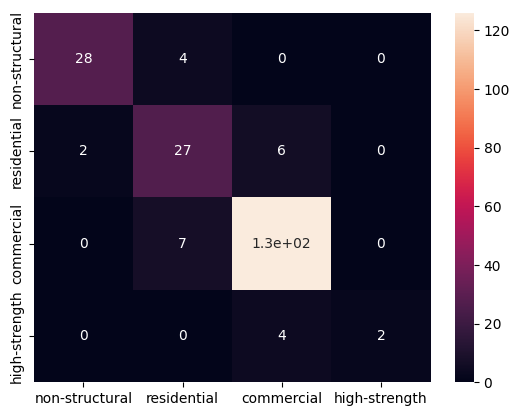

In [40]:
siniflar=['non-structural','residential','commercial','high-strength'] # sınıflar, dayanım sırasıyla
sns.heatmap(confusion_matrix(y_test,rtahmin, labels=siniflar), annot=True, xticklabels=siniflar, yticklabels=siniflar); # satırlar gerçek, sütunlar tahmin

**Sonuç:** Random Forest commercial (133'te 126, f1 0,94) ve non-structural (32'de 28, f1 0,90) sınıflarında çok başarılı. residential sınıfında daha zorlanıyor (35'te 27, f1 0,74); residential betonlar komşu sınıflarla karışıyor. En büyük sorun high-strength sınıfında: 6 betonun sadece 2'sini buldu (recall 0,33), diğerlerini commercial sandı. Bu sınıfta eğitim verisinde sadece 30 örnek vardı. Hataların neredeyse hepsi komşu sınıflar arasında; model hiçbir zaman non-structural bir betonu high-strength sanmıyor.

### Deep Learning: Keras

**Ne yapıyoruz:** Keras sayısal etiket beklediği için derslerdeki sözlük ve `map` yöntemiyle sınıfları 0-3 arası sayılara çeviriyoruz. Derslerdeki MNIST modelindeki gibi 4 sınıf için son katmanda 4 nöron ve `SparseCategoricalCrossentropy(from_logits=True)` kullanıyoruz. Verileri yine sadece eğitim verisiyle öğretilen StandardScaler ile ölçeklendiriyoruz.

In [41]:
d={'non-structural':0, 'residential':1, 'commercial':2, 'high-strength':3} # sınıf: sayı
y_train_k=y_train.map(d) # eğitim etiketleri
y_test_k=y_test.map(d) # test etiketleri
sc2=StandardScaler() # scaler
x_train_sc2=sc2.fit_transform(x_train) # eğitim verisiyle öğren ve dönüştür
x_test_sc2=sc2.transform(x_test) # test verisini dönüştür

In [42]:
import tensorflow as tf # kayıp fonksiyonu için
model_c=Sequential() # boş model
model_c.add(Dense(64, activation='relu')) # 64 nöronlu gizli katman
model_c.add(Dense(32, activation='relu')) # 32 nöronlu gizli katman
model_c.add(Dense(4)) # 4 sınıf
model_c.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy']) # derslerdeki MNIST ayarları
history_c=model_c.fit(x_train_sc2, y_train_k, epochs=1000, batch_size=16, validation_split=0.2, verbose=0, callbacks=[EarlyStopping(monitor='val_loss', patience=20)]) # modeli eğit
loss,accuracy=model_c.evaluate(x_test_sc2, y_test_k, verbose=0) # test verisiyle ölç
accuracy # test accuracy

0.8543689250946045

In [43]:
kctahmin=np.argmax(model_c.predict(x_test_sc2, verbose=0), axis=1) # en yüksek puanlı sınıf
confusion_matrix(y_test_k, kctahmin) # satırlar gerçek (0-3), sütunlar tahmin

array([[ 27,   5,   0,   0],
       [  3,  24,   8,   0],
       [  0,   7, 123,   3],
       [  0,   0,   4,   2]])

**Sonuç:** Keras modeli accuracy yaklaşık %85,4 aldı; hedefi geçti ama Random Forest'ın (%88,8) gerisinde. Confusion matrix'te (0 non-structural, 1 residential, 2 commercial, 3 high-strength) Random Forest'ta olduğu gibi hataların hepsi komşu sınıflar arasında. high-strength sınıfında 6 betonun 2'sini buldu. Sinir ağı rastgele başladığı için sonuç her çalıştırmada biraz değişebilir.

### Modelleri kaydetme

**Ne yapıyoruz:** En iyi sınıflandırma modelini kaydediyoruz. Regression modeli Problem 1'in sonunda kaydedildi.

In [44]:
import joblib # dosya kaydetme kütüphanesi
joblib.dump(r,'beton_sinif_model.pkl') # en iyi sınıflandırma modeli (Random Forest)
joblib.load('beton_sinif_model.pkl').predict(x_test[:5]), y_test[:5].values # kaydedilen model çalışıyor mu: tahmin ve gerçek

(array(['commercial', 'commercial', 'high-strength', 'commercial',
        'non-structural'], dtype=object),
 <ArrowStringArray>
 ['commercial', 'commercial', 'high-strength', 'commercial', 'non-structural']
 Length: 5, dtype: str)

## Sonuçların Değerlendirilmesi

### Problem 1: Regression

| Model | R² | RMSE (MPa) | MAE (MPa) |
|---|---|---|---|
| XGBoost | 0.917 | 4.62 | 3.03 |
| Gradient Boosting | 0.884 | 5.48 | 4.13 |
| Keras sinir ağı | ~0.83 | ~6.6 | ~4.4 |
| Decision Tree | ~0.83 | ~6.5 | ~4.3 |
| Extra Tree | ~0.81 | ~7.1 | ~4.4 |
| KNN | 0.733 | 8.29 | 6.48 |
| Linear Regression (baseline) | 0.628 | 9.80 | 7.75 |
| Ridge, Lasso, ElasticNet | 0.628 | 9.80 | 7.74 |

**Hedef R² > 0.80 idi; ulaşıldı.** Başlangıç modeli Linear Regression R² 0,628 aldı; en iyi model XGBoost 0,917'ye ulaştı ve ortalama 3 MPa hatayla tahmin yapıyor. Doğrusal modellerin başarısız, ağaç modellerinin başarılı olması, ödevde belirtildiği gibi dayanımın malzemelerin ve yaşın doğrusal olmayan bir fonksiyonu olduğunu doğruluyor.

### Problem 2: Classification

| Model | Accuracy |
|---|---|
| Random Forest | 0.888 |
| Gradient Boosting | 0.883 |
| Decision Tree | ~0.86 |
| Keras sinir ağı | ~0.85 |
| Logistic Regression (baseline) | 0.796 |
| KNN | 0.733 |
| AdaBoost | 0.728 |
| Bernoulli NB | 0.607 |
| Multinomial NB | 0.427 |

**Hedef accuracy > 0.80 idi; ulaşıldı.** En iyi model Random Forest (%88,8). Ancak sınıflar dengesiz olduğu için az örnekli high-strength sınıfında başarı düşük: 6 betonun sadece 2'si bulundu.

### Ödevin istedikleri

1. **Veri scikit-learn'e uygun:** Bütün sütunlar sayısal, boş veri yok; Problem 2'deki metin sütunları get_dummies ile 0-1 sütunlara çevrildi.
2. **Özellikler ve hedef ayrıldı:** Problem 1'de 8 özellik ve Strength, Problem 2'de 9 özellik ve ConcreteClass.
3. **Başlangıç skoru:** Regression'da Linear Regression R² 0,628; classification'da Logistic Regression %79,6.
4. **Veri yeterliliği:** 824 eğitim ve 206 test örneği, 8-9 özellikli modeller için yeterli. Sadece high-strength sınıfında (eğitimde 30, testte 6 örnek) veri yetersiz.
5. **En az 7 klasik algoritma ve derin öğrenme:** Regression'da 9, classification'da 8 klasik algoritma ve her iki problemde Keras modeli kullanıldı.

En iyi modeller `beton_dayanim_model.pkl` (XGBoost) ve `beton_sinif_model.pkl` (Random Forest) olarak kaydedildi.

## Kodun Değerlendirilmesi

Derslerdeki yöntemler kullanıldı: EDA, korelasyon, train_test_split, Linear ve Logistic Regression ile başlangıç modelleri, derslerdeki regression ve classification `algo_test` fonksiyonları, StandardScaler, Keras Sequential modelleri ve EarlyStopping, classification report ve confusion matrix, joblib. Ödevde verilen sütun adları, green_classifier ve strength_classifer fonksiyonları aynen kullanıldı. StandardScaler sadece eğitim verisiyle öğretildi; test verisi hiçbir modelin eğitiminde kullanılmadı.

## Eksikler ve Sınırlılıklar

- Veride 25 tekrar eden satır var; derslerde tekrar silme yöntemi görülmediği için silinmedi.
- Classification'da high-strength sınıfı çok az örnekli; bu sınıf için daha fazla veri veya sınıf dengesizliğini gideren yöntemler (ör. derslerde bahsedilen SMOTE) gerekir.
- Derslerdeki classification algo_test, precision, recall ve f1'i average='micro' ile hesapladığı için bu değerler accuracy ile aynı çıkıyor; sınıf bazında başarı classification report'tan okunmalı.
- algo_test içindeki ağaç modellerinde ve Keras modellerinde rastgelelik olduğu için ~ işaretli değerler her çalıştırmada biraz değişebilir.
- TensorFlow ilk yüklendiğinde bilgi mesajları yazdırıyor; bunlar hata değil.